# 07 - Regression models: the pump surface done properly, virtual sensors and severity

The earlier version of this project fitted a second-order polynomial for pump flow from pressure
rise and speed and reported R^2 = 0.997 and RMSE = 0.010 L/min. Those figures came from a shuffled split of
200 ms samples, where every test point has near-identical neighbours in the training set. This notebook
takes that idea and asks the questions a model going into a digital twin has to answer:

1. **Which polynomial degree?** Chosen by how well it predicts a speed it never saw, not by R^2.
2. **Do machine-learning regressors do better?** Random forest, gradient boosting, a neural network,
   a Gaussian process, and a hybrid of the physics model with a Gaussian process.
3. **How sure is the model?** Prediction intervals, and whether they hold on another test day. That is
   what an alarm limit should be built from, instead of a fixed +/- 0.03 L/min.
4. **Virtual sensors for the rig.** Can the flow be predicted from the pressures, so a failed or
   drifting flow meter can be spotted?
5. **Severity regression.** How far has a fault progressed, from the sensor readings alone?

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fueltwin import config, features, plotting as pl, pump, pumpmodel as pm, regression as rg

warnings.filterwarnings("ignore")
pl.use_style()
pd.set_option("display.precision", 4)
pd.set_option("display.width", 170)
pt = pump.load_all()
fin = pt[(pt["campaign"] == "final") & (pt["dP_pump"] < 3.3)]
ini = pt[pt["campaign"] == "initial"]
ver = pd.read_csv(config.TABLE_DIR / "05_verification_points.csv")
ini_clean = []
for _, g in ini.groupby("test"):
    on = pm.relief_onset(g)["onset_dP_bar"]
    ini_clean.append(g[g["dP_pump"] < (min(3.0, on - 0.1) if np.isfinite(on) else 3.0)])
ini_clean = pd.concat(ini_clean)
w = features.load_windows(1.0)

## 1. Choosing the polynomial degree

Each degree from 1 to 5 is fitted to the final campaign. "Training fit" is what the earlier version
reported; "held-out speed" fits five speeds and predicts the sixth, in turn.

In [2]:
deg_rows = []
for deg in range(1, 6):
    m = rg.poly_pump(deg)
    train_r2 = 1 - np.var(m.fit(fin["rpm"], fin["dP_pump"], fin["Q"]).predict(fin["rpm"], fin["dP_pump"]) - fin["Q"]) / np.var(fin["Q"])
    loso = pm.leave_one_speed_out(fin, lambda deg=deg: [rg.poly_pump(deg)])
    vm = pm.metrics(ver["Q_measured"], m.predict(ver["rpm"], ver["dP"]))
    im = pm.metrics(ini_clean["Q"], m.predict(ini_clean["rpm"], ini_clean["dP_pump"]))
    deg_rows.append({"degree": deg, "training R2": train_r2, "held-out speed RMSE (L/min)": loso["rmse_Lpm"].mean(),
                     "worst held-out speed RMSE": loso["rmse_Lpm"].max(),
                     "verification points RMSE": vm["rmse_Lpm"], "2021 campaign RMSE": im["rmse_Lpm"]})
deg_tab = pd.DataFrame(deg_rows).set_index("degree")
deg_tab.to_csv(config.TABLE_DIR / "07_polynomial_degree.csv")
deg_tab

,training R2,held-out speed RMSE (L/min),worst held-out speed RMSE,verification points RMSE,2021 campaign RMSE
degree,,,,,
1,0.9968,0.0120,0.0160,0.0489,0.0922
2,0.9973,0.0130,0.0206,0.0487,0.0833
3,0.9979,0.0105,0.0161,0.0478,0.2119
4,0.9981,0.0168,0.0504,0.0482,0.2161
5,0.9981,0.0187,0.0598,0.0482,0.2136


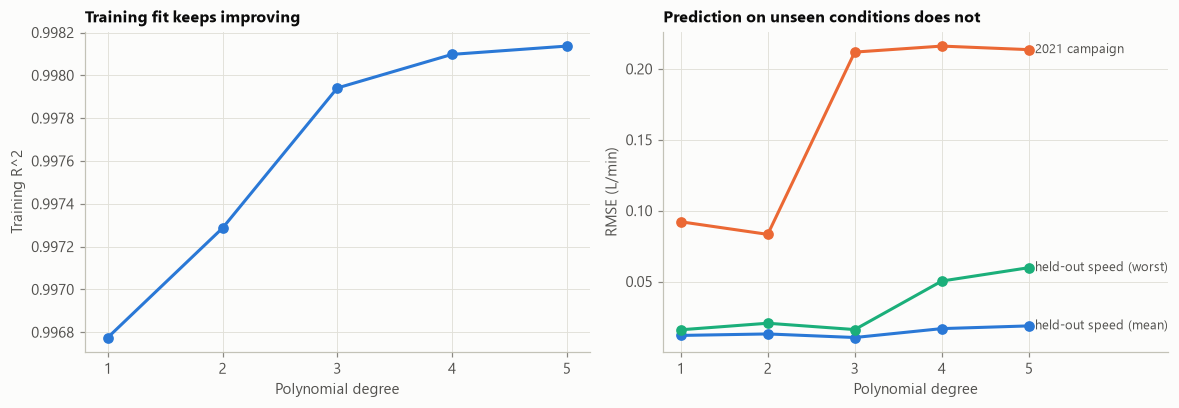

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(deg_tab.index, deg_tab["training R2"], marker="o", color=pl.SERIES[0])
axes[0].set_title("Training fit keeps improving")
axes[0].set_ylabel("Training R^2")
for col, c, lab in [("held-out speed RMSE (L/min)", pl.SERIES[0], "held-out speed (mean)"),
                    ("worst held-out speed RMSE", pl.SERIES[2], "held-out speed (worst)"),
                    ("2021 campaign RMSE", pl.SERIES[1], "2021 campaign")]:
    axes[1].plot(deg_tab.index, deg_tab[col], marker="o", color=c)
    pl.label_end(axes[1], 5, deg_tab[col].iloc[-1], lab)
axes[1].set_title("Prediction on unseen conditions does not")
axes[1].set_ylabel("RMSE (L/min)")
axes[1].set_xlim(0.8, 6.6)
for ax in axes:
    ax.set_xlabel("Polynomial degree")
    ax.set_xticks(range(1, 6))
fig.tight_layout()
pl.save(fig, "07_polynomial_degree")
plt.show()

Training R^2 rises with every extra degree, which is why it is a poor guide. On a held-out speed the
error is lowest at degree 3 and grows from degree 4 (the curve starts to bend where there is no data
to support it). On the 2021 campaign, which runs from 400 to 1140 rpm, degrees 3-5 are **more than
twice as wrong** as degrees 1-2 (0.21 against 0.08-0.09 L/min): their extra curvature extrapolates
badly outside the 700-950 rpm training range, on top of the day-to-day shift every model carries.
**Degree 2, as in the earlier version, is the better compromise; the reported R^2 just did not measure what the
model would do in use.**

## 2. Machine-learning regressors for the pump

Same three tests for every model: held-out speed within the final campaign, the 24 independent
verification points, and the 2021 campaign (below the relief valve). The Gaussian-process models are
fitted on 0.05 bar bins of the data (about 250 points) to keep them tractable.

In [4]:
rows = []
for rpm in sorted(fin["nominal_rpm"].unique()):
    tr, te = fin[fin["nominal_rpm"] != rpm], fin[fin["nominal_rpm"] == rpm]
    for m in rg.ml_pump_models():
        m.fit(tr["rpm"], tr["dP_pump"], tr["Q"])
        r = {"model": m.name, "test": "held-out speed", "speed": rpm, **pm.metrics(te["Q"], m.predict(te["rpm"], te["dP_pump"]))}
        if isinstance(m, rg.GPPump):
            r["95% interval coverage"] = rg.interval_coverage(m, te["rpm"], te["dP_pump"], te["Q"])
        rows.append(r)
full_models = {m.name: m.fit(fin["rpm"], fin["dP_pump"], fin["Q"]) for m in rg.ml_pump_models()}
for name, m in full_models.items():
    for test, (rr, dd, qq) in {"verification points": (ver["rpm"], ver["dP"], ver["Q_measured"]),
                              "2021 campaign": (ini_clean["rpm"], ini_clean["dP_pump"], ini_clean["Q"])}.items():
        r = {"model": name, "test": test, **pm.metrics(qq, m.predict(rr, dd))}
        if isinstance(m, rg.GPPump):
            r["95% interval coverage"] = rg.interval_coverage(m, rr, dd, qq)
        rows.append(r)
ml = pd.DataFrame(rows)
ml.to_csv(config.TABLE_DIR / "07_pump_regressors.csv", index=False)
summary = ml.groupby(["model", "test"], sort=False)[["rmse_Lpm", "bias_Lpm", "95% interval coverage"]].mean().unstack("test")
summary.round(4)

rmse_Lpm                                         bias_Lpm                                   95% interval coverage                      \
test                  held-out speed verification points 2021 campaign held-out speed verification points 2021 campaign        held-out speed verification points   
model                                                                                                                                                               
physics (D, k_s)              0.0156              0.0477        0.0997         0.0000              0.0455        0.0944                   NaN                 NaN   
polynomial degree 2           0.0130              0.0487        0.0833         0.0003              0.0477        0.0746                   NaN                 NaN   
polynomial degree 3           0.0105              0.0478        0.2119         0.0029              0.0469        0.1559                   NaN                 NaN   
random forest                 0.1124              0.0442        0.3333        -0.0356              0.0328        0.2061                   NaN                 NaN   
gradient boosting             0.1097              0.0441        0.3333        -0.0381              0.0329        0.2059                   NaN                 NaN   
neural network (MLP)          0.0632              0.0482        0.2349         0.0252              0.0462        0.1946                   NaN                 NaN   
Gaussian process              0.0172              0.0479        0.3270         0.0064              0.0472        0.1803                0.6781                 0.0   
physics + GP (hybrid)         0.0135              0.0476        0.0994        -0.0002              0.0468        0.0936                0.8947                 0.0   

                                     
test                  2021 campaign  
model                                
physics (D, k_s)                NaN  
polynomial degree 2             NaN  
polynomial degree 3             NaN  
random forest                   NaN  
gradient boosting               NaN  
neural network (MLP)            NaN  
Gaussian process             0.1559  
physics + GP (hybrid)        0.0000

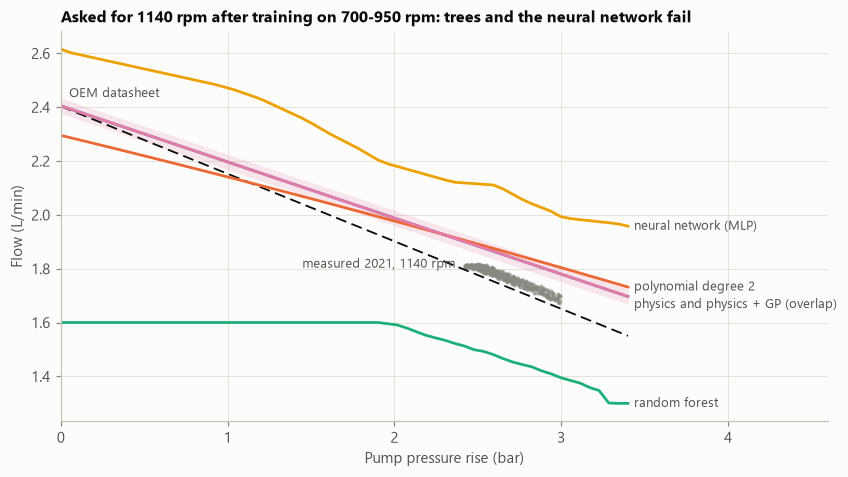

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.6))
dp = np.linspace(0, 3.4, 60)
d1140 = ini_clean[ini_clean["nominal_rpm"] == 1140]
ax.scatter(d1140["dP_pump"], d1140["Q"], s=3, color=pl.MUTED, alpha=0.5, zorder=1)
pl.label_end(ax, d1140["dP_pump"].min(), d1140["Q"].max(), "measured 2021, 1140 rpm", dx=-6, ha="right")
ax.plot(dp, pm.oem_flow(1140, dp), color=pl.INK, lw=1.2, ls=(0, (6, 3)))
pl.label_end(ax, 0.05, pm.oem_flow(1140, 0.05) + 0.06, "OEM datasheet", dx=0)
show = ["physics (D, k_s)", "polynomial degree 2", "random forest", "neural network (MLP)", "physics + GP (hybrid)"]
for i, name in enumerate(show):
    q = full_models[name].predict(np.full_like(dp, 1140), dp)
    ax.plot(dp, q, lw=1.8, color=pl.SERIES[i])
    if name != "physics (D, k_s)":
        pl.label_end(ax, dp[-1], q[-1] - (0.03 if "hybrid" in name else 0),
                     "physics and physics + GP (overlap)" if "hybrid" in name else name)
mu, sd = full_models["physics + GP (hybrid)"].predict_dist(np.full_like(dp, 1140), dp)
ax.fill_between(dp, mu - 1.96 * sd, mu + 1.96 * sd, color=pl.SERIES[4], alpha=0.18, lw=0)
ax.set_xlim(0, 4.6)
ax.set_xlabel("Pump pressure rise (bar)")
ax.set_ylabel("Flow (L/min)")
ax.set_title("Asked for 1140 rpm after training on 700-950 rpm: trees and the neural network fail")
pl.save(fig, "07_regressors_extrapolation")
plt.show()

**What the comparison shows**

* **Tree models (random forest, gradient boosting) cannot predict an unseen speed at all.** They split
  the speed axis into steps, so a held-out speed gets the flow of its neighbour; their held-out error
  (0.11 L/min) is about seven times the physics model's. At 1140 rpm they return the 950 rpm curve,
  and on the 2021 campaign their error is 0.33 L/min.
* The **neural network** interpolates but is unstable at the edges of the data (0.06 held out).
* A **Gaussian process alone** interpolates well between speeds but drifts back towards the average
  outside them (0.33 L/min on the 2021 campaign).
* The best group on held-out speeds is the **degree 2-3 polynomials and the hybrid** (physics model plus
  a Gaussian process that learns only what the physics misses), all at 0.011-0.014 L/min. The hybrid is
  not the most accurate; what it adds is a **prediction interval** and physics-like behaviour outside the
  data, because its GP correction fades back to zero there (its 2021 error equals the physics model's).
* On the verification points every model carries the same day-to-day bias of about +0.045 L/min
  (+3 to +4 %); on the 2021 campaign the low-degree models are biased by +0.07 to +0.09 L/min. No
  regressor can learn a shift that is not in its training data.

## 3. How sure is the pump model? Intervals for alarm limits

The earlier version set the alarm at +/- 0.03 L/min, or 3 sd of healthy residuals. The hybrid model gives
an interval for every prediction instead. The question is whether it holds.

In [6]:
cov = ml[ml["model"] == "physics + GP (hybrid)"].groupby("test", sort=False)["95% interval coverage"].mean()
hyb = full_models["physics + GP (hybrid)"]
_, sd_ver = hyb.predict_dist(ver["rpm"], ver["dP"])
day_shift = (hyb.predict(ver["rpm"], ver["dP"]) - ver["Q_measured"]).mean()
print("95 % interval coverage of the hybrid model:")
print(cov.round(3).to_string())
print(f"\nTypical predictive sd at the verification points: {sd_ver.mean():.4f} L/min")
print(f"Mean day-to-day shift on the verification day:     {day_shift:+.4f} L/min")

95 % interval coverage of the hybrid model:
test
held-out speed         0.895
verification points    0.000
2021 campaign          0.000

Typical predictive sd at the verification points: 0.0097 L/min
Mean day-to-day shift on the verification day:     +0.0468 L/min


* On a **held-out speed from the same day** the intervals cover most of the data: the model knows
  what it does not know about speed.
* On **another day** coverage falls to **zero**: the intervals describe the scatter within one test
  day (sd about 0.01 L/min) while the day-to-day shift is about 0.05 L/min.

So a sound alarm limit for the pump residual has two parts: the model's own interval, plus a
day-to-day term that only repeated healthy tests across days (and a temperature measurement) can
estimate. A fixed +/- 0.03 L/min is narrower than the day-to-day shift alone, and would raise alarms
on a healthy pump on a different day. In notebook 08 the day-to-day term is handled by tracking the
pump's slip as a slowly changing state instead of a fixed number.

## 4. Virtual flow meters for the rig

A flow meter can fail or drift. If flow can be predicted from the pressures, the twin has a second,
independent estimate (analytical redundancy). Each candidate is trained on every recording **except**
one fault and tested on that fault, so it is judged on hydraulics it has not seen.

In [7]:
vrows = []
ok = w["P5_floor_frac"] <= 0.01
for held in config.FAULTS:
    tr, te = w[(w["condition"] != held) & ok], w[(w["condition"] == held) & ok]
    for fm in rg.flow_meters():
        fm.fit(tr)
        e = fm.predict(te) - te["Q"]
        vrows.append({"flow meter": fm.name, "fault never seen": held, "rmse": float(np.sqrt(np.mean(e ** 2)))})
vm = pd.DataFrame(vrows).pivot_table(index="flow meter", columns="fault never seen", values="rmse", sort=False)
vm.to_csv(config.TABLE_DIR / "07_virtual_flow_meters.csv")
vm.round(4)

fault never seen,F1,F2,F3,F4,F5
flow meter,,,,,
physics: P5 -> pipe law,0.0116,0.0476,0.0108,0.0972,0.0217
"linear: P4, P5",0.0062,0.0072,0.0158,0.0177,0.1892
linear: all pressures,0.0804,0.0114,0.0648,0.0154,0.3217
polynomial 2: all pressures,3.3094,0.0182,0.3314,0.0177,0.0803
random forest: all pressures,0.0138,0.0261,0.0166,0.0394,0.0526
gradient boosting: all pressures,0.0147,0.0564,0.0167,0.0318,0.0872


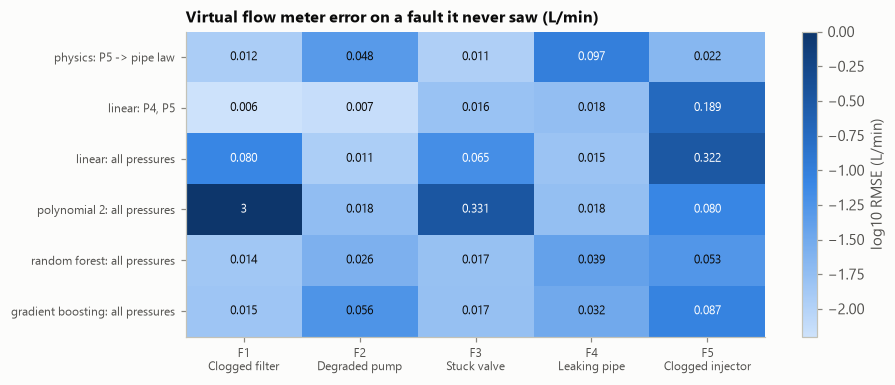

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
show = np.log10(vm.clip(lower=1e-4))
im = ax.imshow(show.to_numpy(), cmap=pl.BLUE_RAMP, vmin=-2.2, vmax=0, aspect="auto")
for i in range(vm.shape[0]):
    for j in range(vm.shape[1]):
        v = vm.iloc[i, j]
        ax.text(j, i, f"{v:.3f}" if v < 1 else f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="white" if show.iloc[i, j] > -1.2 else pl.INK)
ax.set_xticks(range(vm.shape[1]), [f"{c}\n{config.CONDITION_NAMES[c]}" for c in vm.columns], fontsize=8)
ax.set_yticks(range(vm.shape[0]), vm.index, fontsize=8)
ax.grid(False)
cb = fig.colorbar(im, ax=ax)
cb.set_label("log10 RMSE (L/min)")
ax.set_title("Virtual flow meter error on a fault it never saw (L/min)")
pl.save(fig, "07_virtual_flow_meters")
plt.show()

* **No single virtual meter works for every fault.** Each relies on some part of the circuit staying
  healthy, and fails on the fault that changes that part. The linear P4/P5 meter relies on the nozzle,
  so it fails when the nozzle clogs (F5); the physics meter relies on P5, so it fails where P5 is
  near its floor (strong pump and leak faults).
* The **degree-2 polynomial on all pressures explodes** on unseen faults (up to 3.3 L/min): it
  extrapolates its curvature into pressure combinations it never saw. Flexible models are the riskiest
  choice for a sensor that must work during a fault.
* The practical design is **several independent virtual meters and a vote**: a flow-meter fault shows
  up as the meter disagreeing with all of them, while a hydraulic fault shows up as the virtual meters
  disagreeing with each other in a pattern that points to the faulty section.

How small a flow-meter error could be caught? A bias is added to healthy flow readings and the linear
P4/P5 meter (trained without any healthy windows) watches for it, in two ways:

* **absolute**: the residual must exceed the meter's own error across all operating points;
* **relative to its healthy baseline**: the residual is compared with its value during healthy runs
  HC-1 to HC-3 (calibration), and the bias is added to HC-4 to HC-6 (test).

In [9]:
cal = w[(w["condition"] != "HC") & ok & (w["condition"] != "F5")]
lin = rg.flow_meters()[1].fit(cal)
r_cal = cal["Q"] - lin.predict(cal)
thr_abs = 4 * 1.4826 * np.median(np.abs(r_cal - np.median(r_cal)))
hc = w[w["condition"] == "HC"]
base_runs, test_runs = ["HC-1", "HC-2", "HC-3"], ["HC-4", "HC-5", "HC-6"]
r_base = hc.loc[hc["run_id"].isin(base_runs), "Q"] - lin.predict(hc[hc["run_id"].isin(base_runs)])
mu_b, thr_rel = r_base.mean(), 4 * r_base.std()
test = hc[hc["run_id"].isin(test_runs)]
brows = []
for bias in [0.0, 0.005, 0.01, 0.02, 0.05, 0.1]:
    resid = test["Q"] * (1 + bias) - lin.predict(test)
    brows.append({"flow-meter bias": f"{100 * bias:.1f} %",
                  "flagged, absolute limit": float((resid.abs() > thr_abs).mean()),
                  "flagged, relative to healthy baseline": float(((resid - mu_b).abs() > thr_rel).mean())})
print(f"absolute limit: {thr_abs:.4f} L/min | healthy-baseline limit: {thr_rel:.4f} L/min (4 sd)")
pd.DataFrame(brows)

absolute limit: 0.0449 L/min | healthy-baseline limit: 0.0079 L/min (4 sd)


,flow-meter bias,"flagged, absolute limit","flagged, relative to healthy baseline"
0,0.0 %,0.0,0.0000
1,0.5 %,0.0,0.0167
2,1.0 %,0.0,0.3556
3,2.0 %,0.0,1.0000
4,5.0 %,0.0,1.0000
5,10.0 %,1.0,1.0000


* Judged against its error across all operating conditions (+/- 0.045 L/min, about 6 % of healthy
  flow), the virtual meter only catches a flow-meter fault of about 10 %.
* Judged against **its own behaviour during recent healthy running**, the same meter catches a 2 %
  bias in every window (and a 1 % bias in about a third of them). A virtual sensor is a precise tool for spotting a *change* and a blunt one
  for an absolute check.

In the twin this check belongs to the data-quality function (FE5 in the design document): a flow-meter
fault must be separated from a hydraulic fault before any diagnosis is trusted, and it is best done as
change detection against recent healthy behaviour (notebook 08).

## 5. Severity regression: how far has the fault progressed?

For a known fault, regress the valve setting on the six sensor readings. Each recording is predicted
by a model that never saw it (leave one recording out within that fault), and compared with the
physics route from notebook 04 (a monotone map from the physical severity indicator).

In [10]:
srows, spts = [], []
for f in config.FAULTS:
    d = w[w["condition"] == f]
    for name, mk in rg.severity_models().items():
        errs = []
        for run in d["run_id"].unique():
            tr, te = d[d["run_id"] != run], d[d["run_id"] == run]
            p = mk().fit(tr[rg.SEVERITY_FEATURES], tr["severity"]).predict(te[rg.SEVERITY_FEATURES])
            errs.append(np.mean(np.abs(p - te["severity"])))
            spts.append({"fault": f, "model": name, "actual": te["severity"].iloc[0], "predicted": float(np.mean(p))})
        srows.append({"fault": f, "model": name, "MAE (valve-travel points)": np.mean(errs)})
sev = pd.DataFrame(srows).pivot_table(index="model", columns="fault", values="MAE (valve-travel points)", sort=False)
phys = pd.read_csv(config.TABLE_DIR / "04_severity.csv").set_index("fault").iloc[:, -1]
sev.loc["physics indicator + monotone map (nb 04)"] = phys
sev["mean"] = sev.mean(axis=1)
sev.to_csv(config.TABLE_DIR / "07_severity_regression.csv")
sev.round(2)

fault,F1,F2,F3,F4,F5,mean
model,,,,,,
linear,4.07,7.44,2.43,4.66,4.90,4.70
polynomial 2,7.47,7.46,1.43,4.82,3.95,5.03
random forest,7.79,9.05,9.04,9.96,7.99,8.77
gradient boosting,8.54,11.26,9.17,8.03,9.82,9.37
physics indicator + monotone map (nb 04),4.49,4.52,4.61,6.36,4.63,4.92


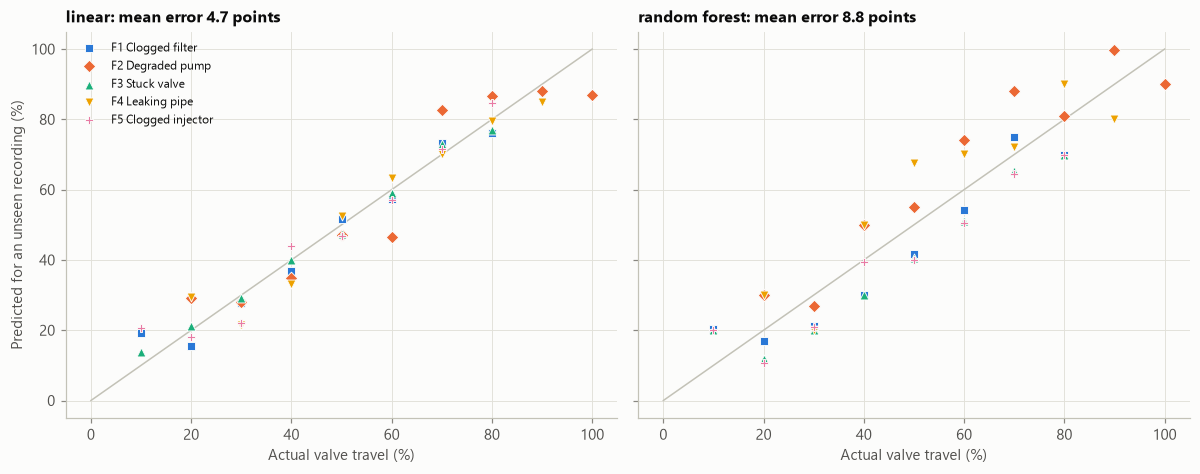

In [11]:
pts = pd.DataFrame(spts)
best = sev["mean"].drop("physics indicator + monotone map (nb 04)").idxmin()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, name in zip(axes, [best, "random forest"]):
    ax.plot([0, 100], [0, 100], color=pl.AXIS, lw=1)
    for f in config.FAULTS:
        d = pts[(pts["model"] == name) & (pts["fault"] == f)]
        ax.scatter(d["actual"], d["predicted"], color=pl.CONDITION_COLORS[f], marker=pl.CONDITION_MARKERS[f], s=34,
                   edgecolor=pl.SURFACE, linewidth=0.6, label=f"{f} {config.CONDITION_NAMES[f]}", zorder=3)
    ax.set_title(f"{name}: mean error {sev.loc[name, 'mean']:.1f} points")
    ax.set_xlabel("Actual valve travel (%)")
axes[0].set_ylabel("Predicted for an unseen recording (%)")
axes[0].legend(fontsize=8)
fig.tight_layout()
pl.save(fig, "07_severity_regression")
plt.show()

* Simple **linear and degree-2 models recover the setting to within a few points** on average, as well
  as or better than the physics route, because within one fault every sensor moves monotonically with
  severity.
* **Tree models are worst**: when the mildest or the strongest setting is held out they can only
  return the nearest setting they saw, so they systematically under-call the extremes, which are
  exactly the settings that matter (first sign of a fault, and imminent failure).
* Caveat: the model is told which fault it is looking at. Severity regression is the second step after
  isolation (notebook 04), not a replacement for it.

## Summary

| Question | Answer |
|---|---|
| Best polynomial degree for the pump | 3 on held-out speeds, but 3-5 extrapolate badly to other speeds; degree 2 (as in the earlier version) is the better compromise. Training R^2 cannot tell |
| Best pump regressor | degree 2-3 polynomials and physics + GP are equally accurate between speeds; the hybrid adds intervals and extrapolates like physics |
| ML regressors without physics | trees cannot predict an unseen speed; the neural network is unstable at the edges |
| Alarm limits | model interval plus a day-to-day term; a fixed +/- 0.03 L/min is narrower than the day-to-day shift |
| Virtual flow meters | each fails on the fault that breaks its assumption; use several and vote; a flow-meter bias of 2 % is detectable as a change from healthy, only about 10 % in absolute terms |
| Severity | linear models recover the valve setting to within a few points; trees fail at the extremes |

The common thread is the one from notebooks 04 and 05: **flexible models fit the data they have and
fail where the physics changes**; models that carry the physics (or that are simple enough not to
invent curvature) are the ones that hold up in a twin.